BrM Nanostring Cosmx 6k (36 Samples, 3M cells)
=======================

In [ ]:
# ==============================================================================
# CosMx Brain Metastasis Spatial Transcriptomics
# ==============================================================================
# %pwd

# 加载相关工具包
from pathlib import Path
import pandas as pd
pd.set_option("display.max_columns", None)

import numpy as np
import os
import matplotlib.pyplot as plt
import palantir
import warnings
import gc
import pickle
import random
import torch

import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity


import anndata as ad

from scipy.stats import gaussian_kde, entropy
from scipy.sparse import csr_matrix
import seaborn as sns

import sklearn
print(sklearn.__version__)  # 应输出 1.3.2

import scanpy as sc
import pyucell as uc

# pip install squidpy==1.3.1 scanpy==1.9.3 anndata==0.9.0 numpy==1.23.5 scipy==1.9.3 pandas==1.5.3 scikit-image==0.19.3 tifffile==2022.10.10 pillow==9.4.0 matplotlib==3.6.3 seaborn==0.12.2 numba==0.56.4 networkx==2.8.8 scikit-learn==1.2.2 statsmodels==0.13.5 omnipath==1.0.7   # 旧版 squidpy 才可以读入 
import squidpy as sq
print(sq.__version__)

import celltypist

# from napari_spatialdata import Interactive
import spatialdata as sd
import spatialdata_io

from scipy.spatial import distance_matrix
from collections import defaultdict

from statannotations.Annotator import Annotator
from itertools import combinations  # 自动生成所有两两配对

warnings.filterwarnings('ignore')
sc.logging.print_header()


1.9.0
1.8.1


/home/dingrong/miniconda3/envs/R453/lib/python3.14/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


Package,Version
pandas,2.3.3
numpy,2.4.3
matplotlib,3.10.9
palantir,1.4.4
torch,2.11.0 (2.10.0)
networkx,3.6.1
scikit-learn,1.9.0
anndata,0.12.16
scipy,1.17.1
seaborn,0.13.2


In [2]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


In [3]:
ad.settings.allow_write_nullable_strings = True  # 开启允许保存字符串类型

fig_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result"
# fig_dir = Path().resolve() / "BM_Cosmx_Py"/"Result"
os.makedirs(fig_dir, exist_ok=True)

# ===================== PLOT SETTINGS =====================
sc.set_figure_params(
	facecolor="white", figsize=(6,6), dpi=300, fontsize=11, frameon=True
)
sc.settings.verbosity = 3
sc.settings.n_jobs = 16
sc.settings.figdir = fig_dir

plt.rcParams["savefig.dpi"] = 300
# plt.rcParams["save.bbox_inches"] = "tight"
plt.rcParams['axes.unicode_minus'] = False


# ===================== UTILITY FUNCTIONS =====================
def save_fig(name, fig_dir):
	plt.savefig(os.path.join(fig_dir, f"{name}.png"), dpi=300, bbox_inches="tight" )
	plt.savefig(os.path.join(fig_dir, f"{name}.pdf"), dpi=300, bbox_inches="tight" )
	# plt.close()

# 自动缩放空间坐标
def auto_scale_spatial(adata, target_scale=1000):
	"""
	自动将空间坐标缩放到 [0, target_scale] 范围
	"""
	x = adata.obsm["spatial"][:, 0]
	y = adata.obsm["spatial"][:, 1]
	# 缩放到 0~1
	x = (x - x.min()) / (x.max() - x.min())
	y = (y - y.min()) / (y.max() - y.min())
	# 放大到目标范围
	x = x * target_scale
	y = y * target_scale
	# 放回
	adata.obsm["spatial"] = np.column_stack([x, y])

def plot_umap_spatial(adata, color_key, fig_dir, suffix=""):
	sc.pl.umap(adata, color=color_key, show=False)   # , save=f"umap_{color_key}{suffix}"
	save_fig(f"umap.{color_key}{suffix}", fig_dir)
	for sid in sample_list:
		sub = adata[adata.obs["sample"] == sid].copy()
		if sub.n_obs < 50:
			continue
		# 修复空间坐标
		# sub.obsm["spatial"] = sub.obs[["CenterX_global_px", "CenterY_global_px"]].values  # 直接提取坐标画出来图是反的，CosMx 仪器：Y 轴向下增大（图像坐标系，左上角为原点）， Matplotlib/squidpy：Y 轴向上增大（数学坐标系，左下角为原点）
		# ✅ 永久翻转 Y 坐标
		x = sub.obs["CenterX_global_px"].values
		y = sub.obs["CenterY_global_px"].values
		y_flipped = y.max() + y.min() - y
		sub.obsm["spatial"] = np.column_stack([x, y_flipped])
		# 即使有 obsm["spatial"]，squidpy 依然会强制检查 adata.uns["spatial"], 强制添加 squidpy 必须要的空结构，解决 KeyError
		sub.uns["spatial"] = {"images": {}}
		# # 自动缩放你的 sub 数据坐标
		# auto_scale_spatial(sub, target_scale=1000)
		# sq.pl.spatial_scatter(sub, color=color_key, size=1, img=False, frameon=False, shape=None)  # , library_key="fov" , palette="tab20" , save=f"spatial.{color_key}.{sid}.{suffix}" # img=False, NanoString CosMx 数据，没有组织病理学图像（H&E）
		sq.pl.spatial_scatter(sub, color=color_key, size=1, img=False, frameon=False, legend_fontsize=4, shape=None)  # , library_key="fov" , save=f"spatial.{color_key}.{sid}.{suffix}"  , squidpy 中 legend_loc 只能填：right / left / top / bottom / center ,  scanpy 支持 legend_loc='outside right'
		# ax.invert_yaxis()  # ✅ 临时翻转 Y 轴，匹配 CosMx 原始图像
		save_fig(f"spatial_{color_key}.{sid}{suffix}", fig_dir)

def plot_enrich_bar(df, x_col, y_col, title, name, fig_dir, topn=15):
	plt.figure(figsize=(10,6))
	df_top = df.head(topn).sort_values(x_col, ascending=True)
	sns.barplot(data=df_top, x=x_col, y=y_col)
	plt.title(title, fontsize=12)
	plt.tight_layout()
	save_fig(name, fig_dir)

def plot_boxplot(df, cols, name, fig_dir, title=""):
	plt.figure(figsize=(10,6))
	ax = df[cols].boxplot(grid=False)
	ax.grid(False)  # 去掉网格线
	plt.title(title)
	plt.tight_layout()
	save_fig(name, fig_dir)

样本信息
---------------------------------------------

In [ ]:
# ===================== GLOBAL CONFIG =====================
project_name = "BM_Cosmx_Py"
out_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result/"
# out_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result.bk/"
fig_dir = os.path.join(out_dir, "figures")
csv_dir = os.path.join(out_dir, "tables")
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)

In [ ]:

adata = sc.read_h5ad(os.path.join(out_dir, f"{project_name}.h5ad"))
adata


【Step 13】 Tumor Core and  Boundary (固定半径邻域 200 + 50% 阈值划分 + 3圈空间标签平滑降噪)
-

In [ ]:

# ==============================================================================
# METHODS: 13. Tumor Core and  Boundary
# Detailed Description: Spatial cellular architecture was comprehensively profiled 
# using Squidpy spatial analysis tools to map cell type distributions across 
# histological sections. Cell-type co-occurrence analysis was performed to identify 
# non-random spatial associations between cellular populations. Neighborhood 
# enrichment statistics were computed to quantify significant spatial interactions, 
# while multi-parameter overlay plots integrated transcriptomic, phenotypic, and 
# spatial data at single-cell resolution to delineate the structural organization 
# of the metastatic brain tumor microenvironment.
# ==============================================================================
print("\n【Step 13】 Tumor Core and  Boundary")
fig_dir = os.path.join(out_dir, "Step13_Region", "Radius_200_36")
csv_dir = os.path.join(out_dir, "Step13_Region", "Radius_200_36")
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)



【Step 13】 Tumor Core and  Boundary


In [ ]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


In [ ]:
for sid in sample_list:
	sub = adata[adata.obs["sample"] == sid].copy()
	# 过滤CellType为空的细胞
	sub = sub[~sub.obs["CellType"].isna()].copy()

	# 样本细胞过少或无恶性细胞则跳过
	if sub.n_obs < 10 or "Malignant_Cell" not in sub.obs["tumor_status"].unique():
		continue

	# 可视化分区结果
	sq.pl.spatial_scatter(sub, color="tumor_region", size=1, img=False, frameon=False, legend_fontsize=4, figsize=(8, 8), shape=None)
	save_fig(f"tumor_core_boundary_smooth_radius{RADIUS}_{sid}", fig_dir)
	plt.close()


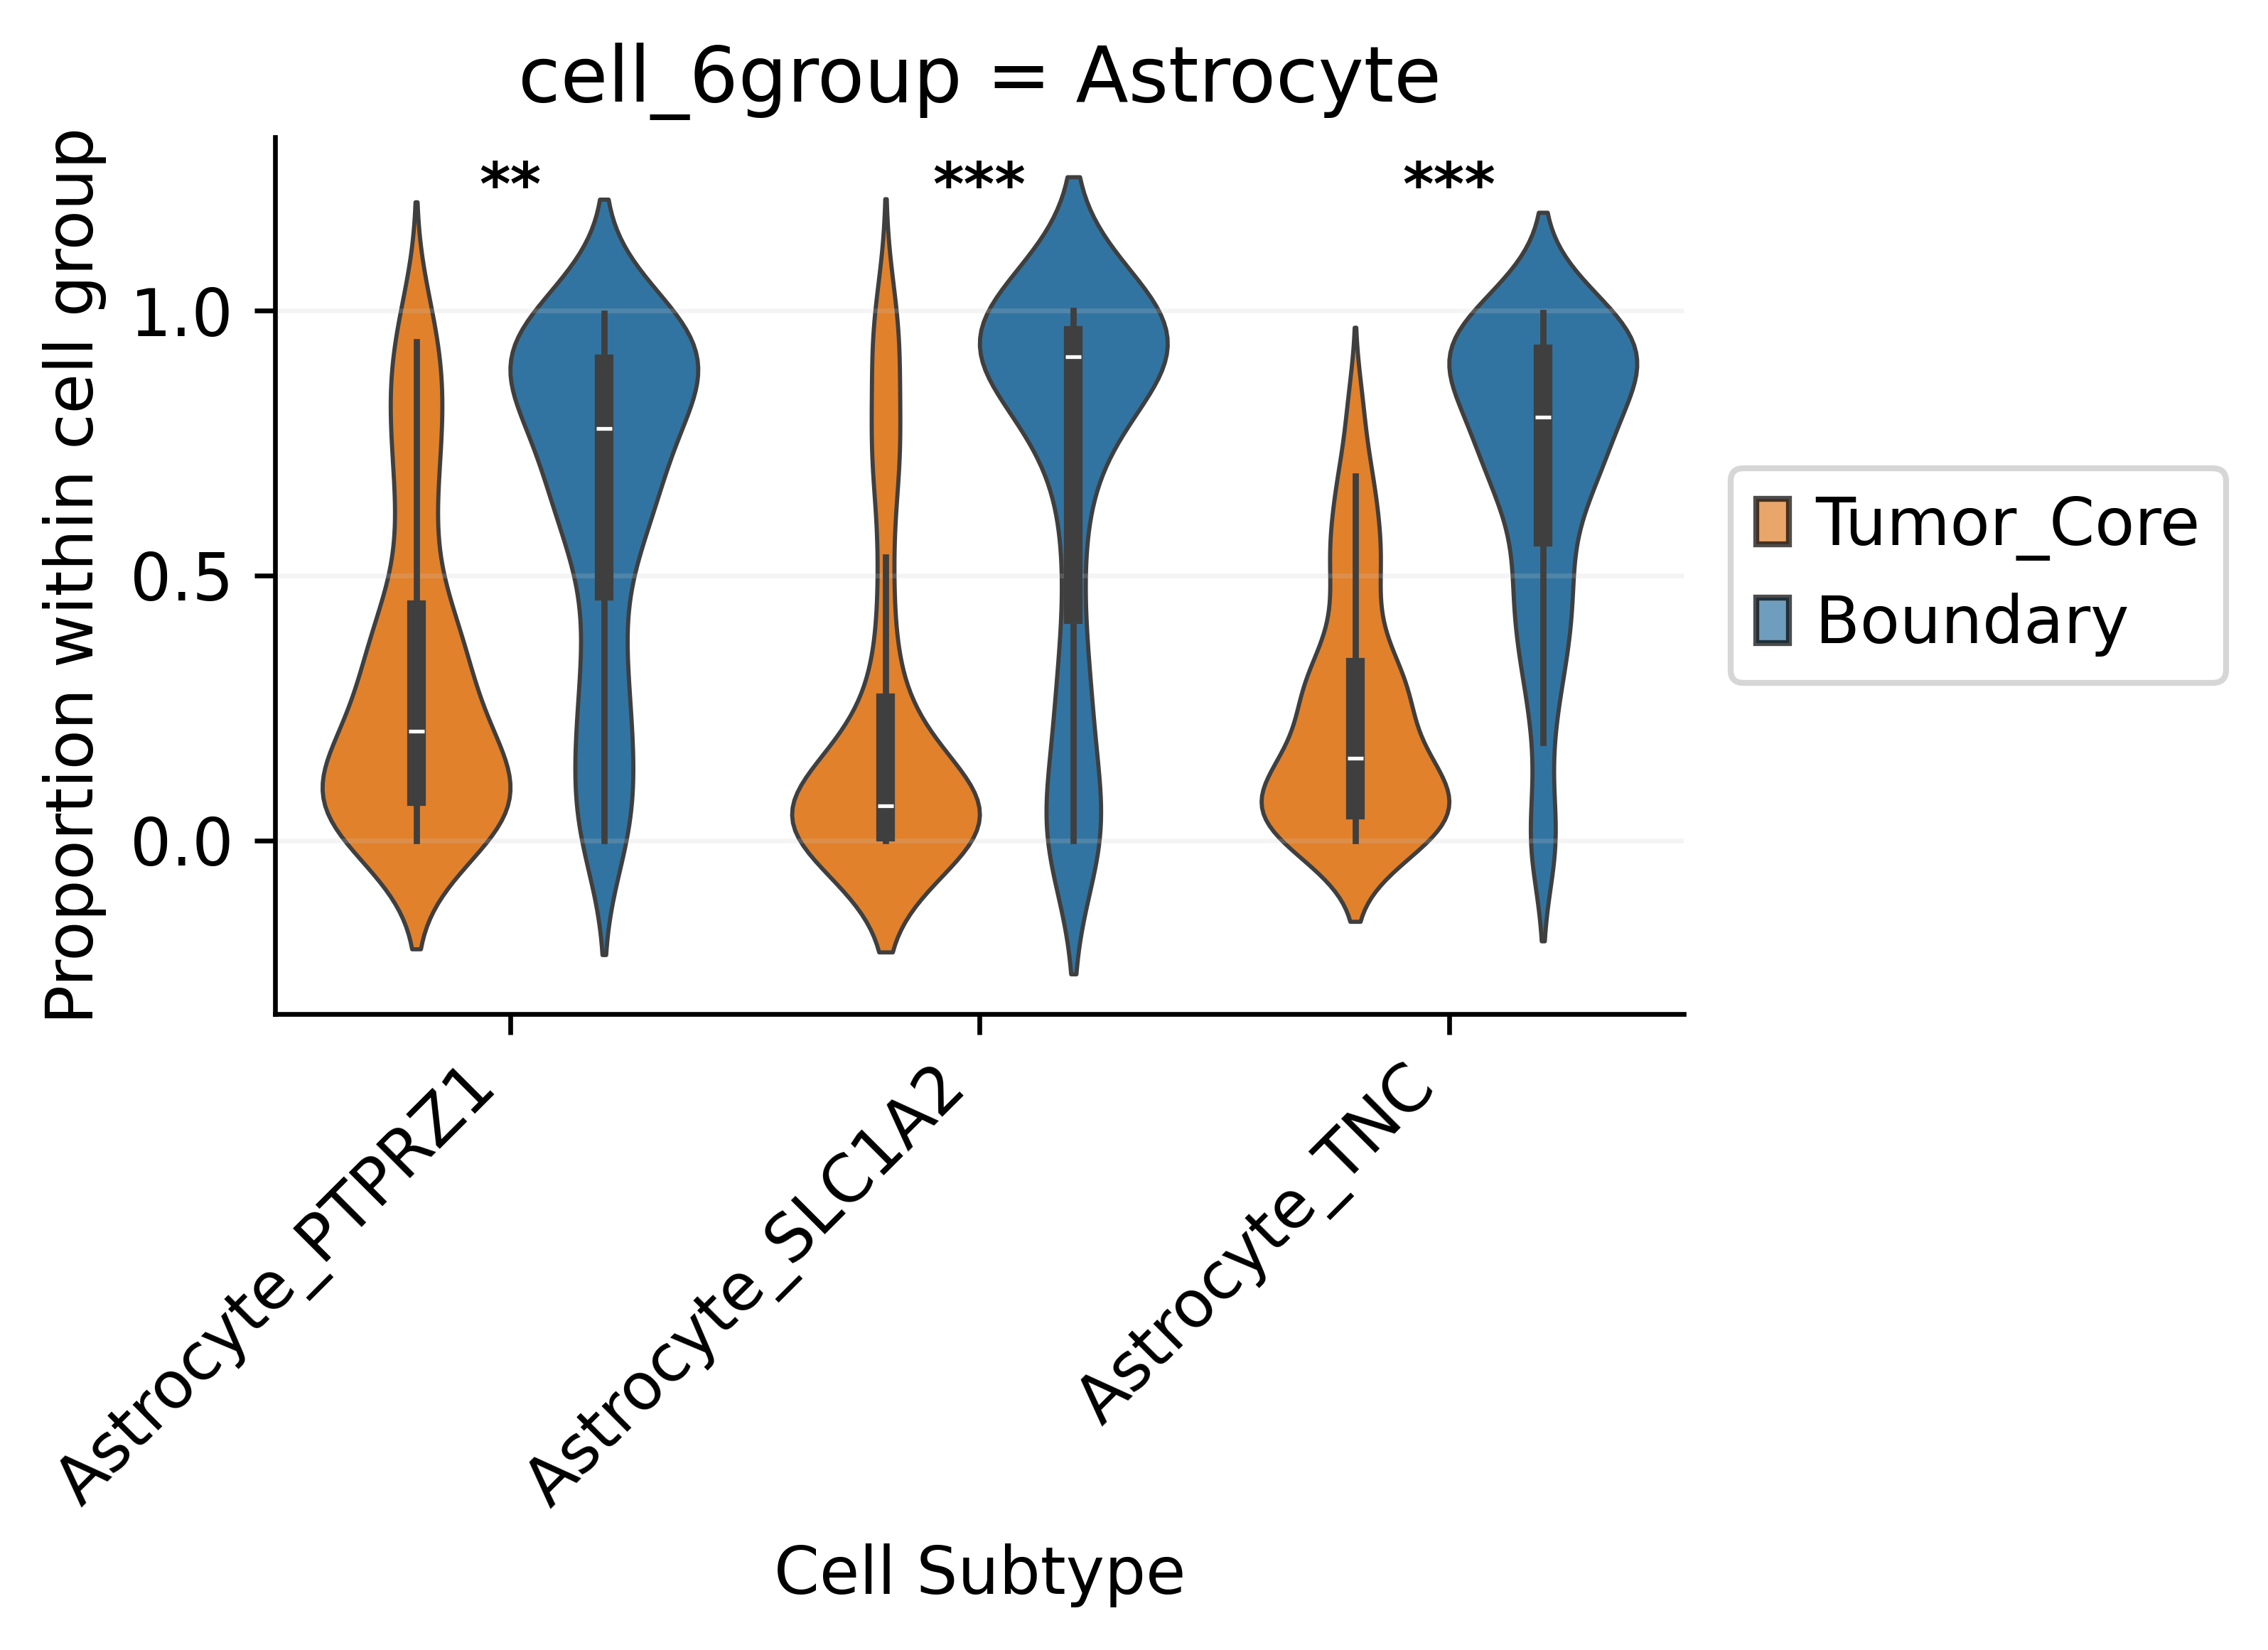

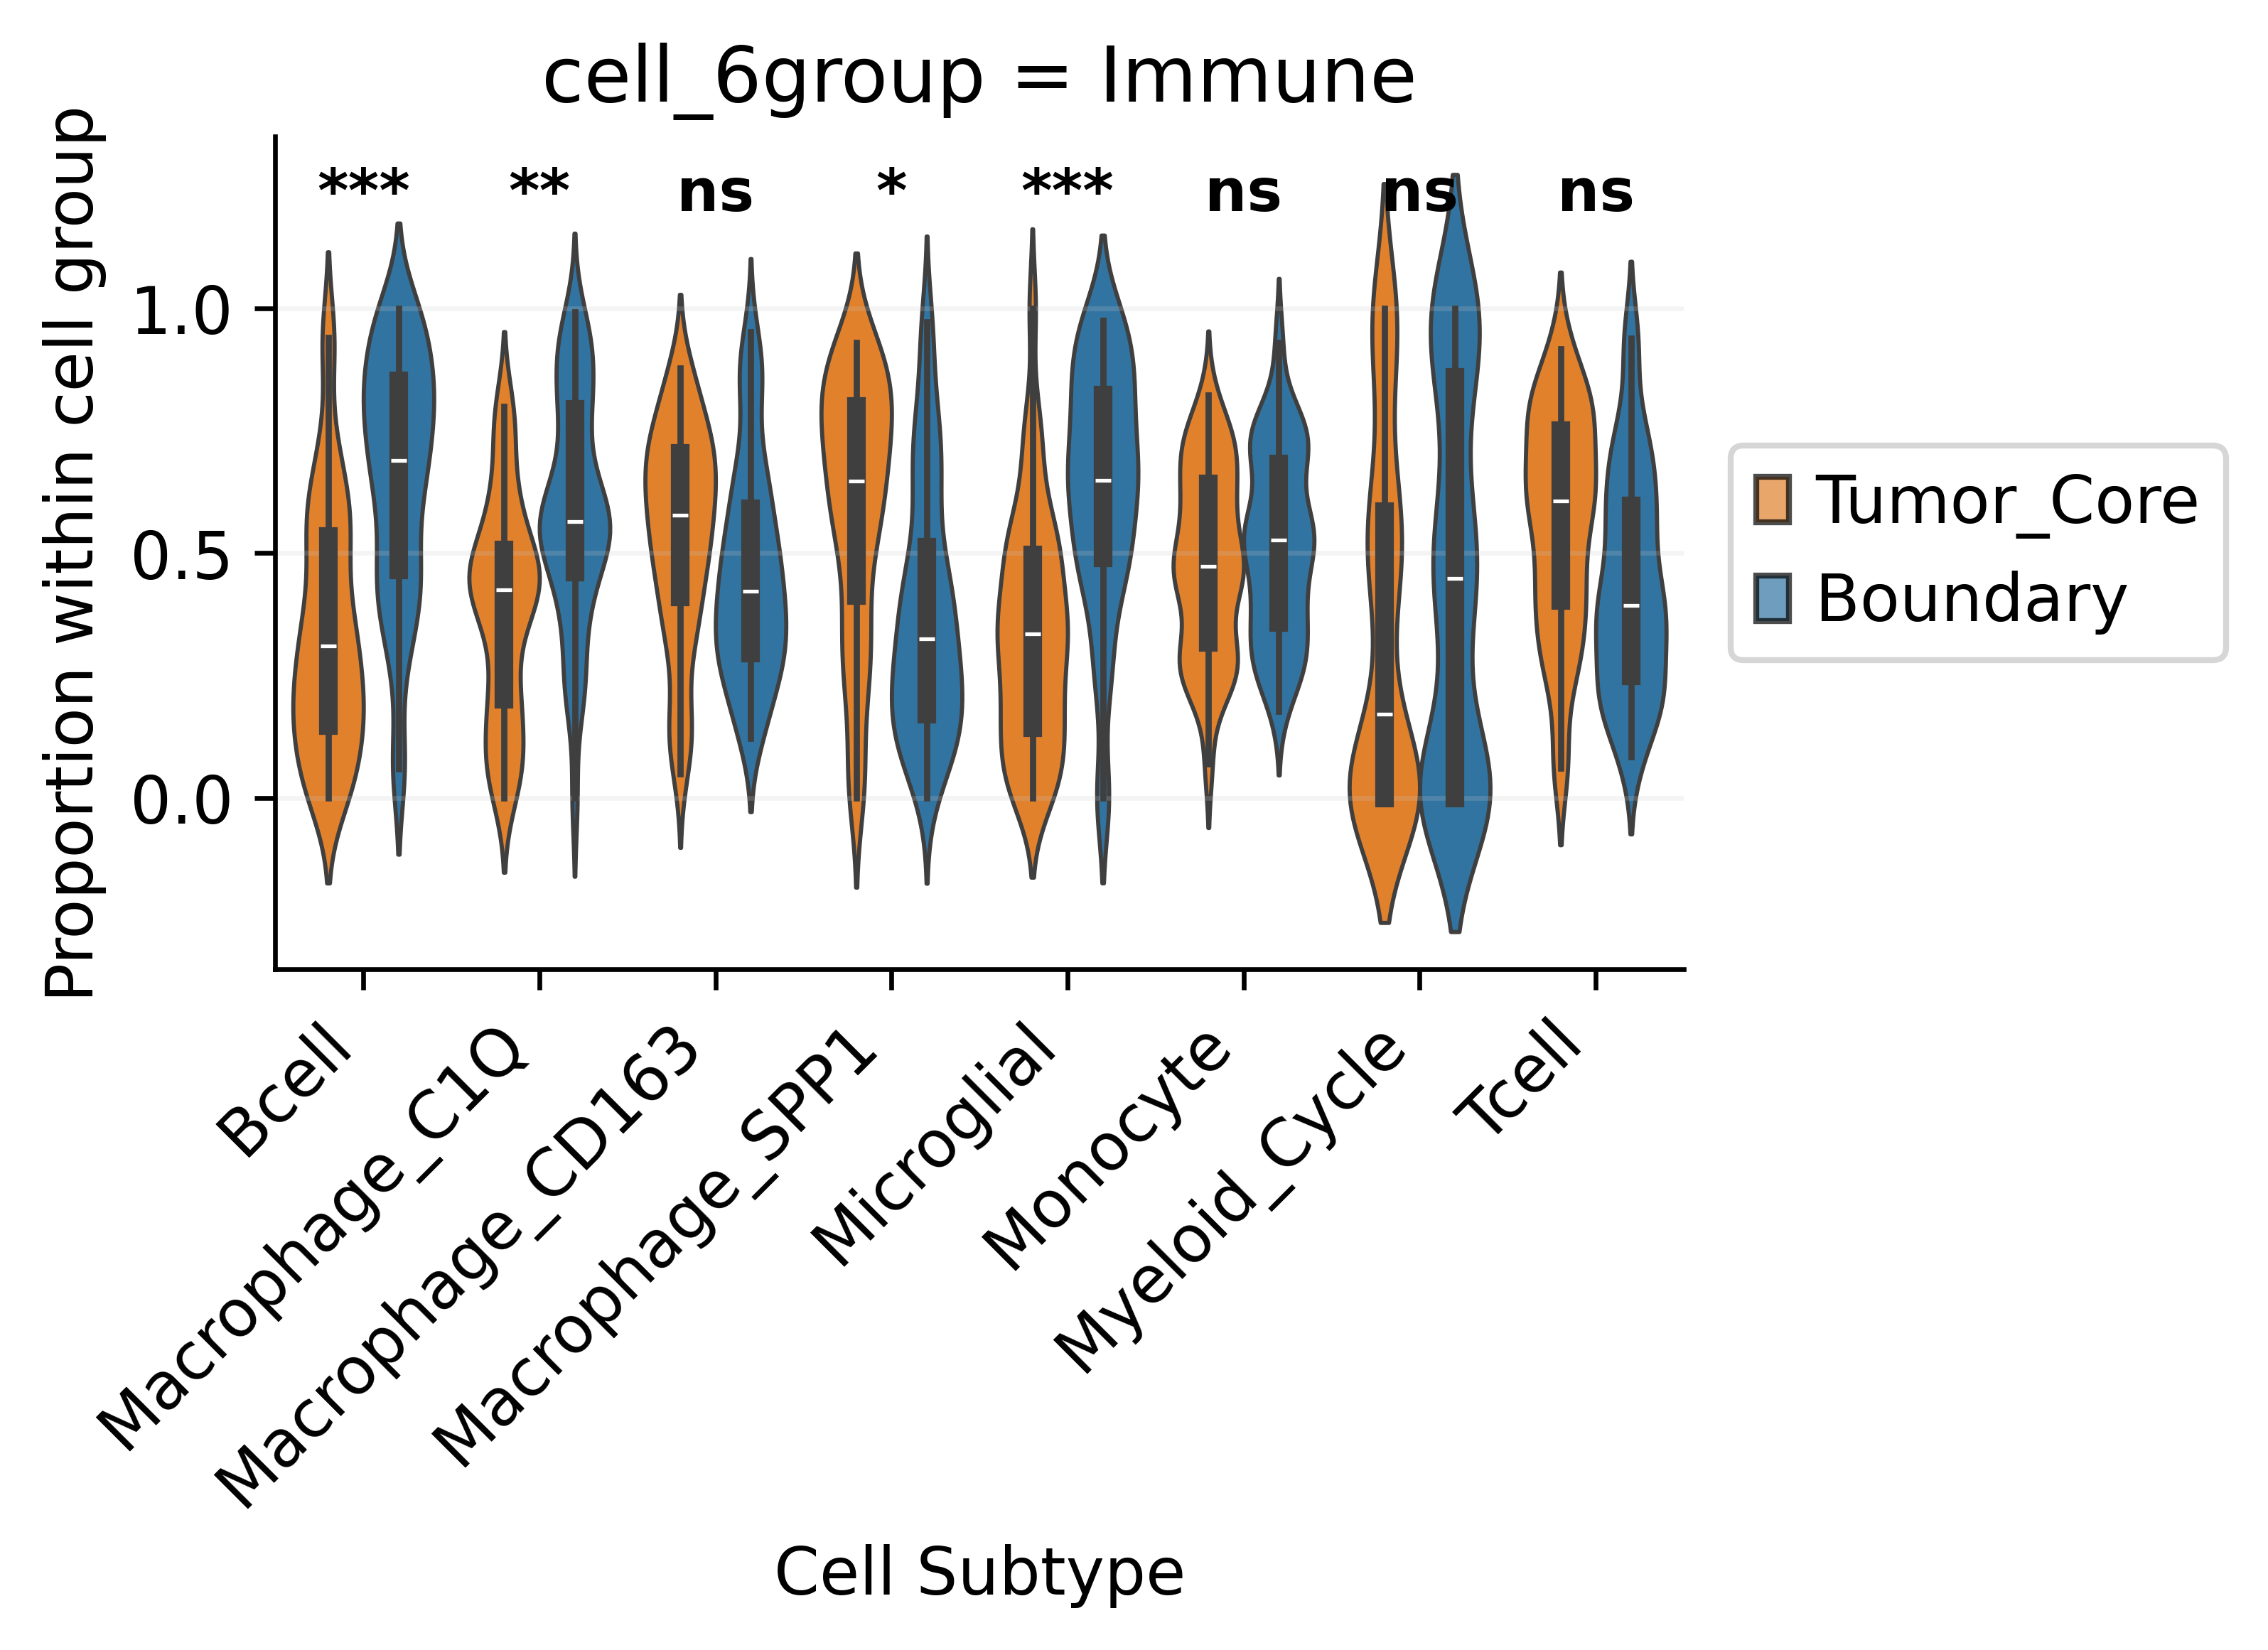

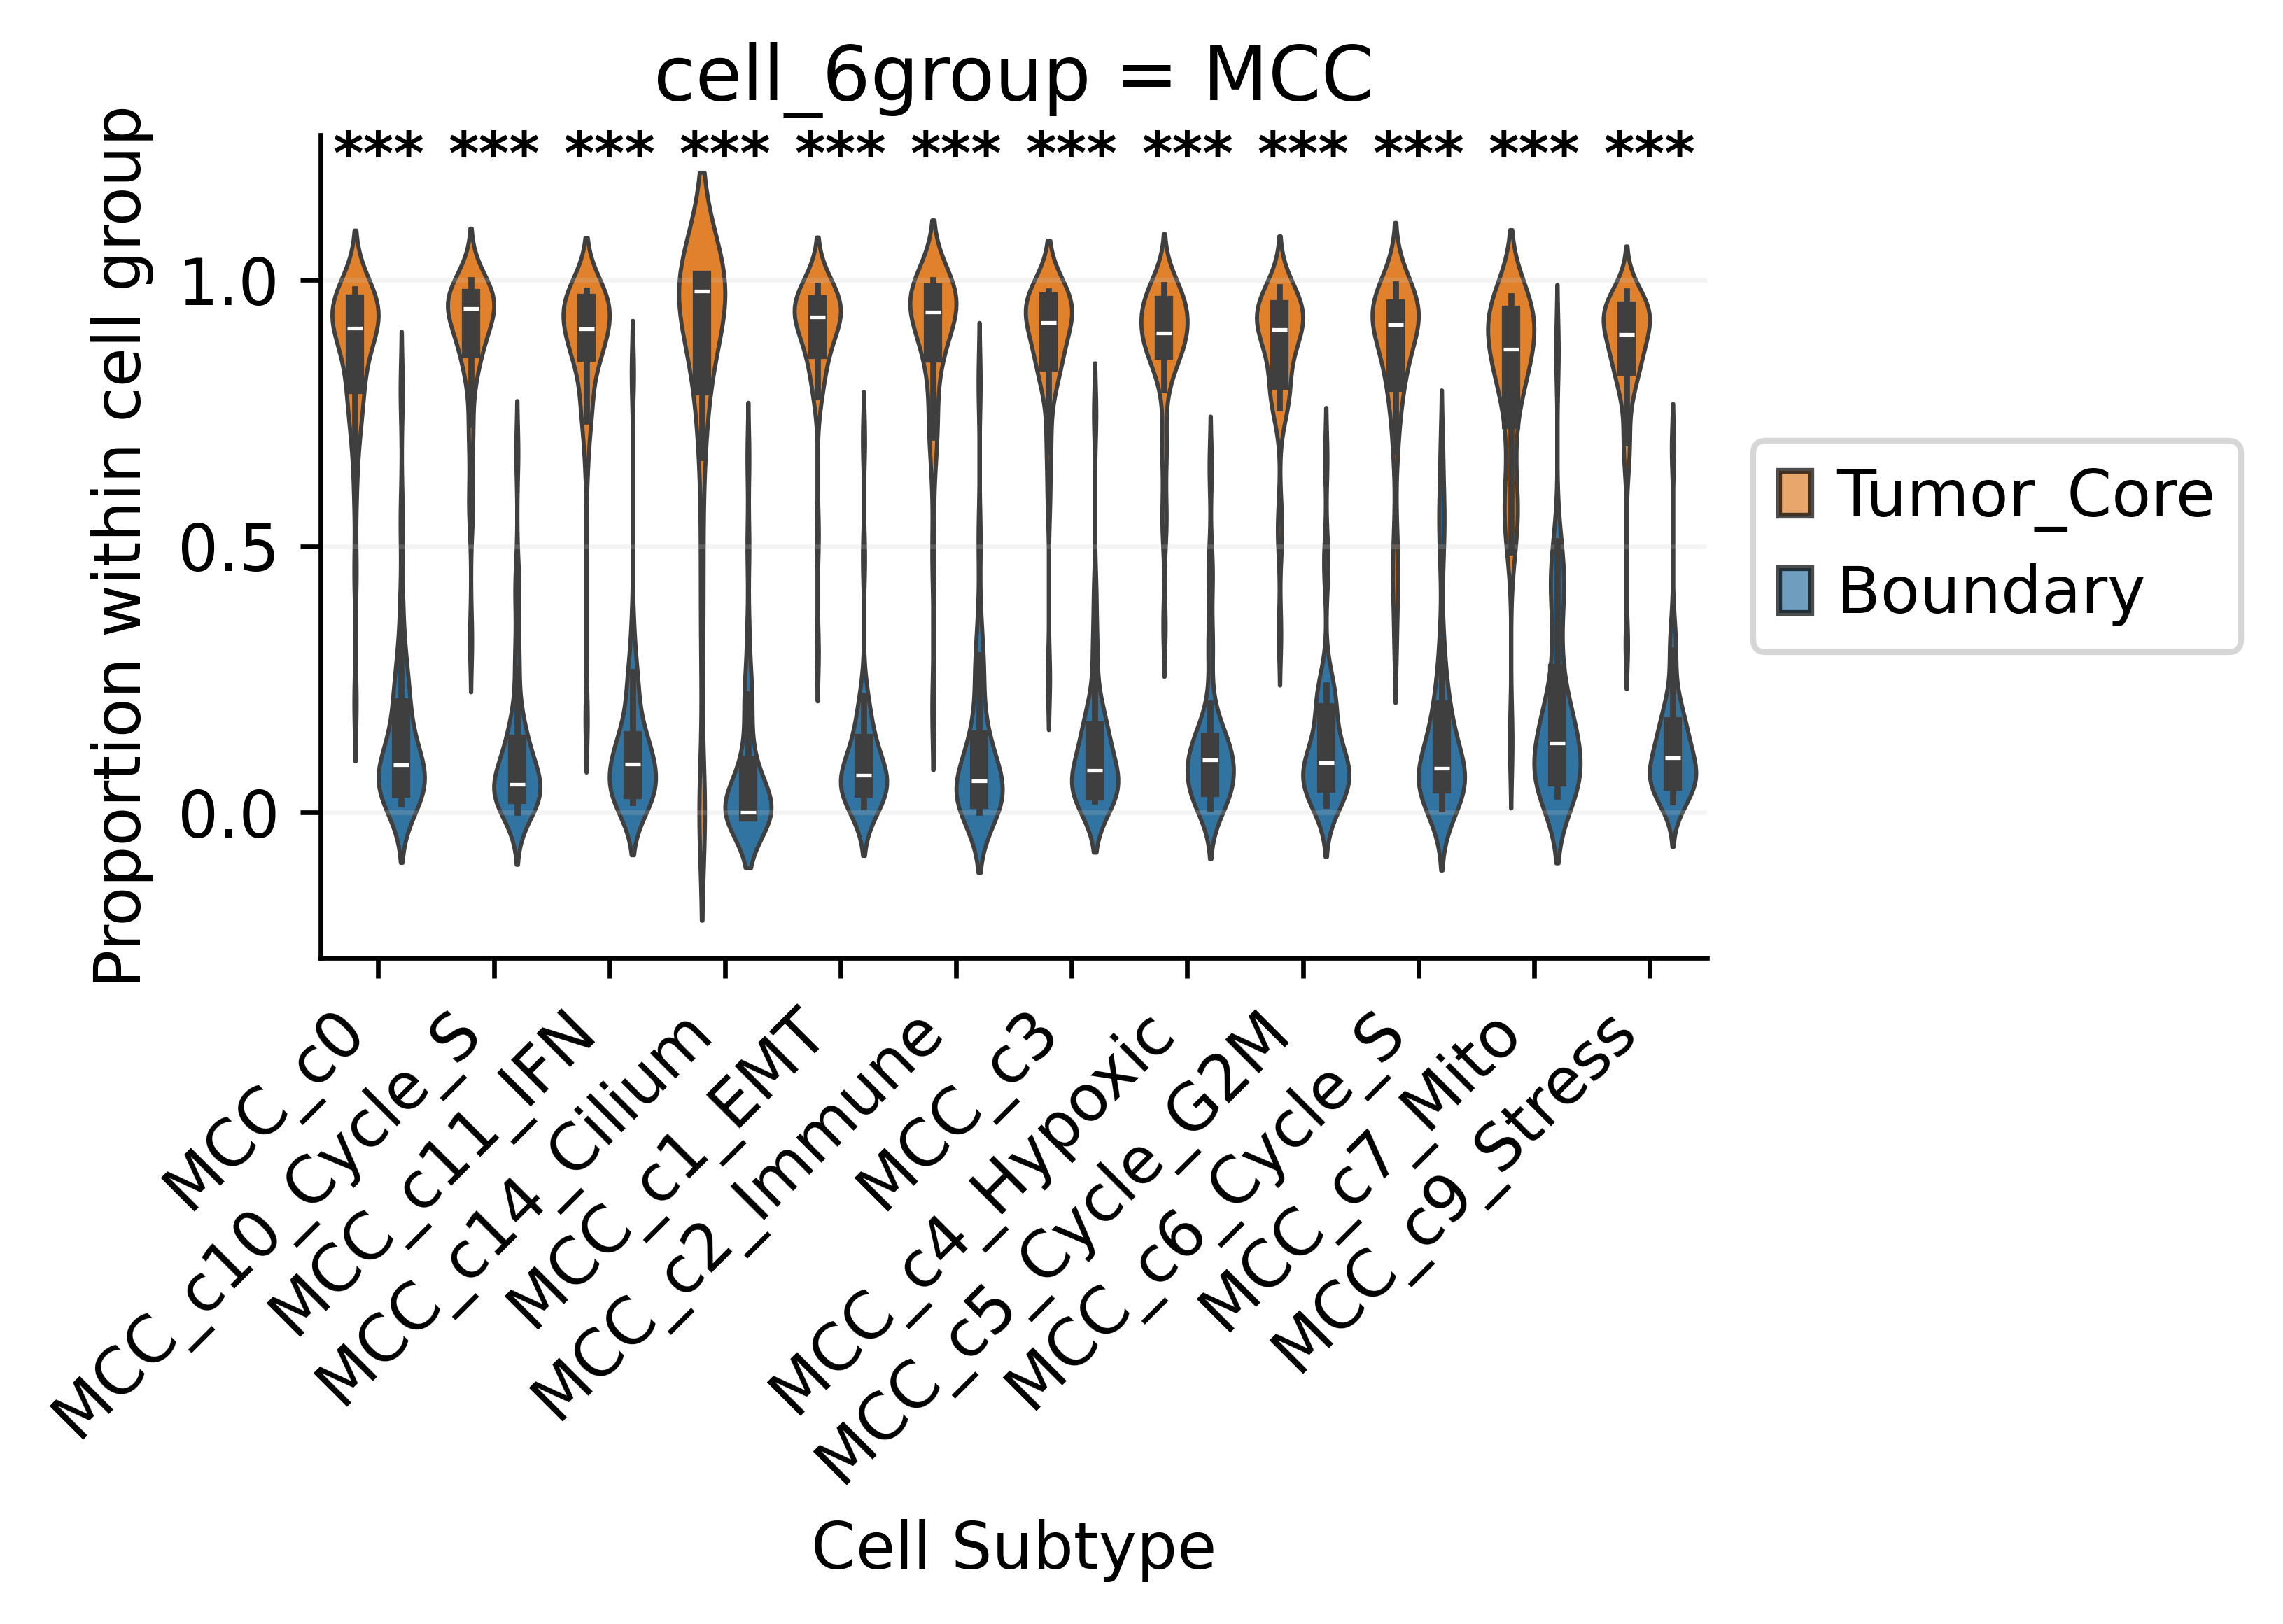

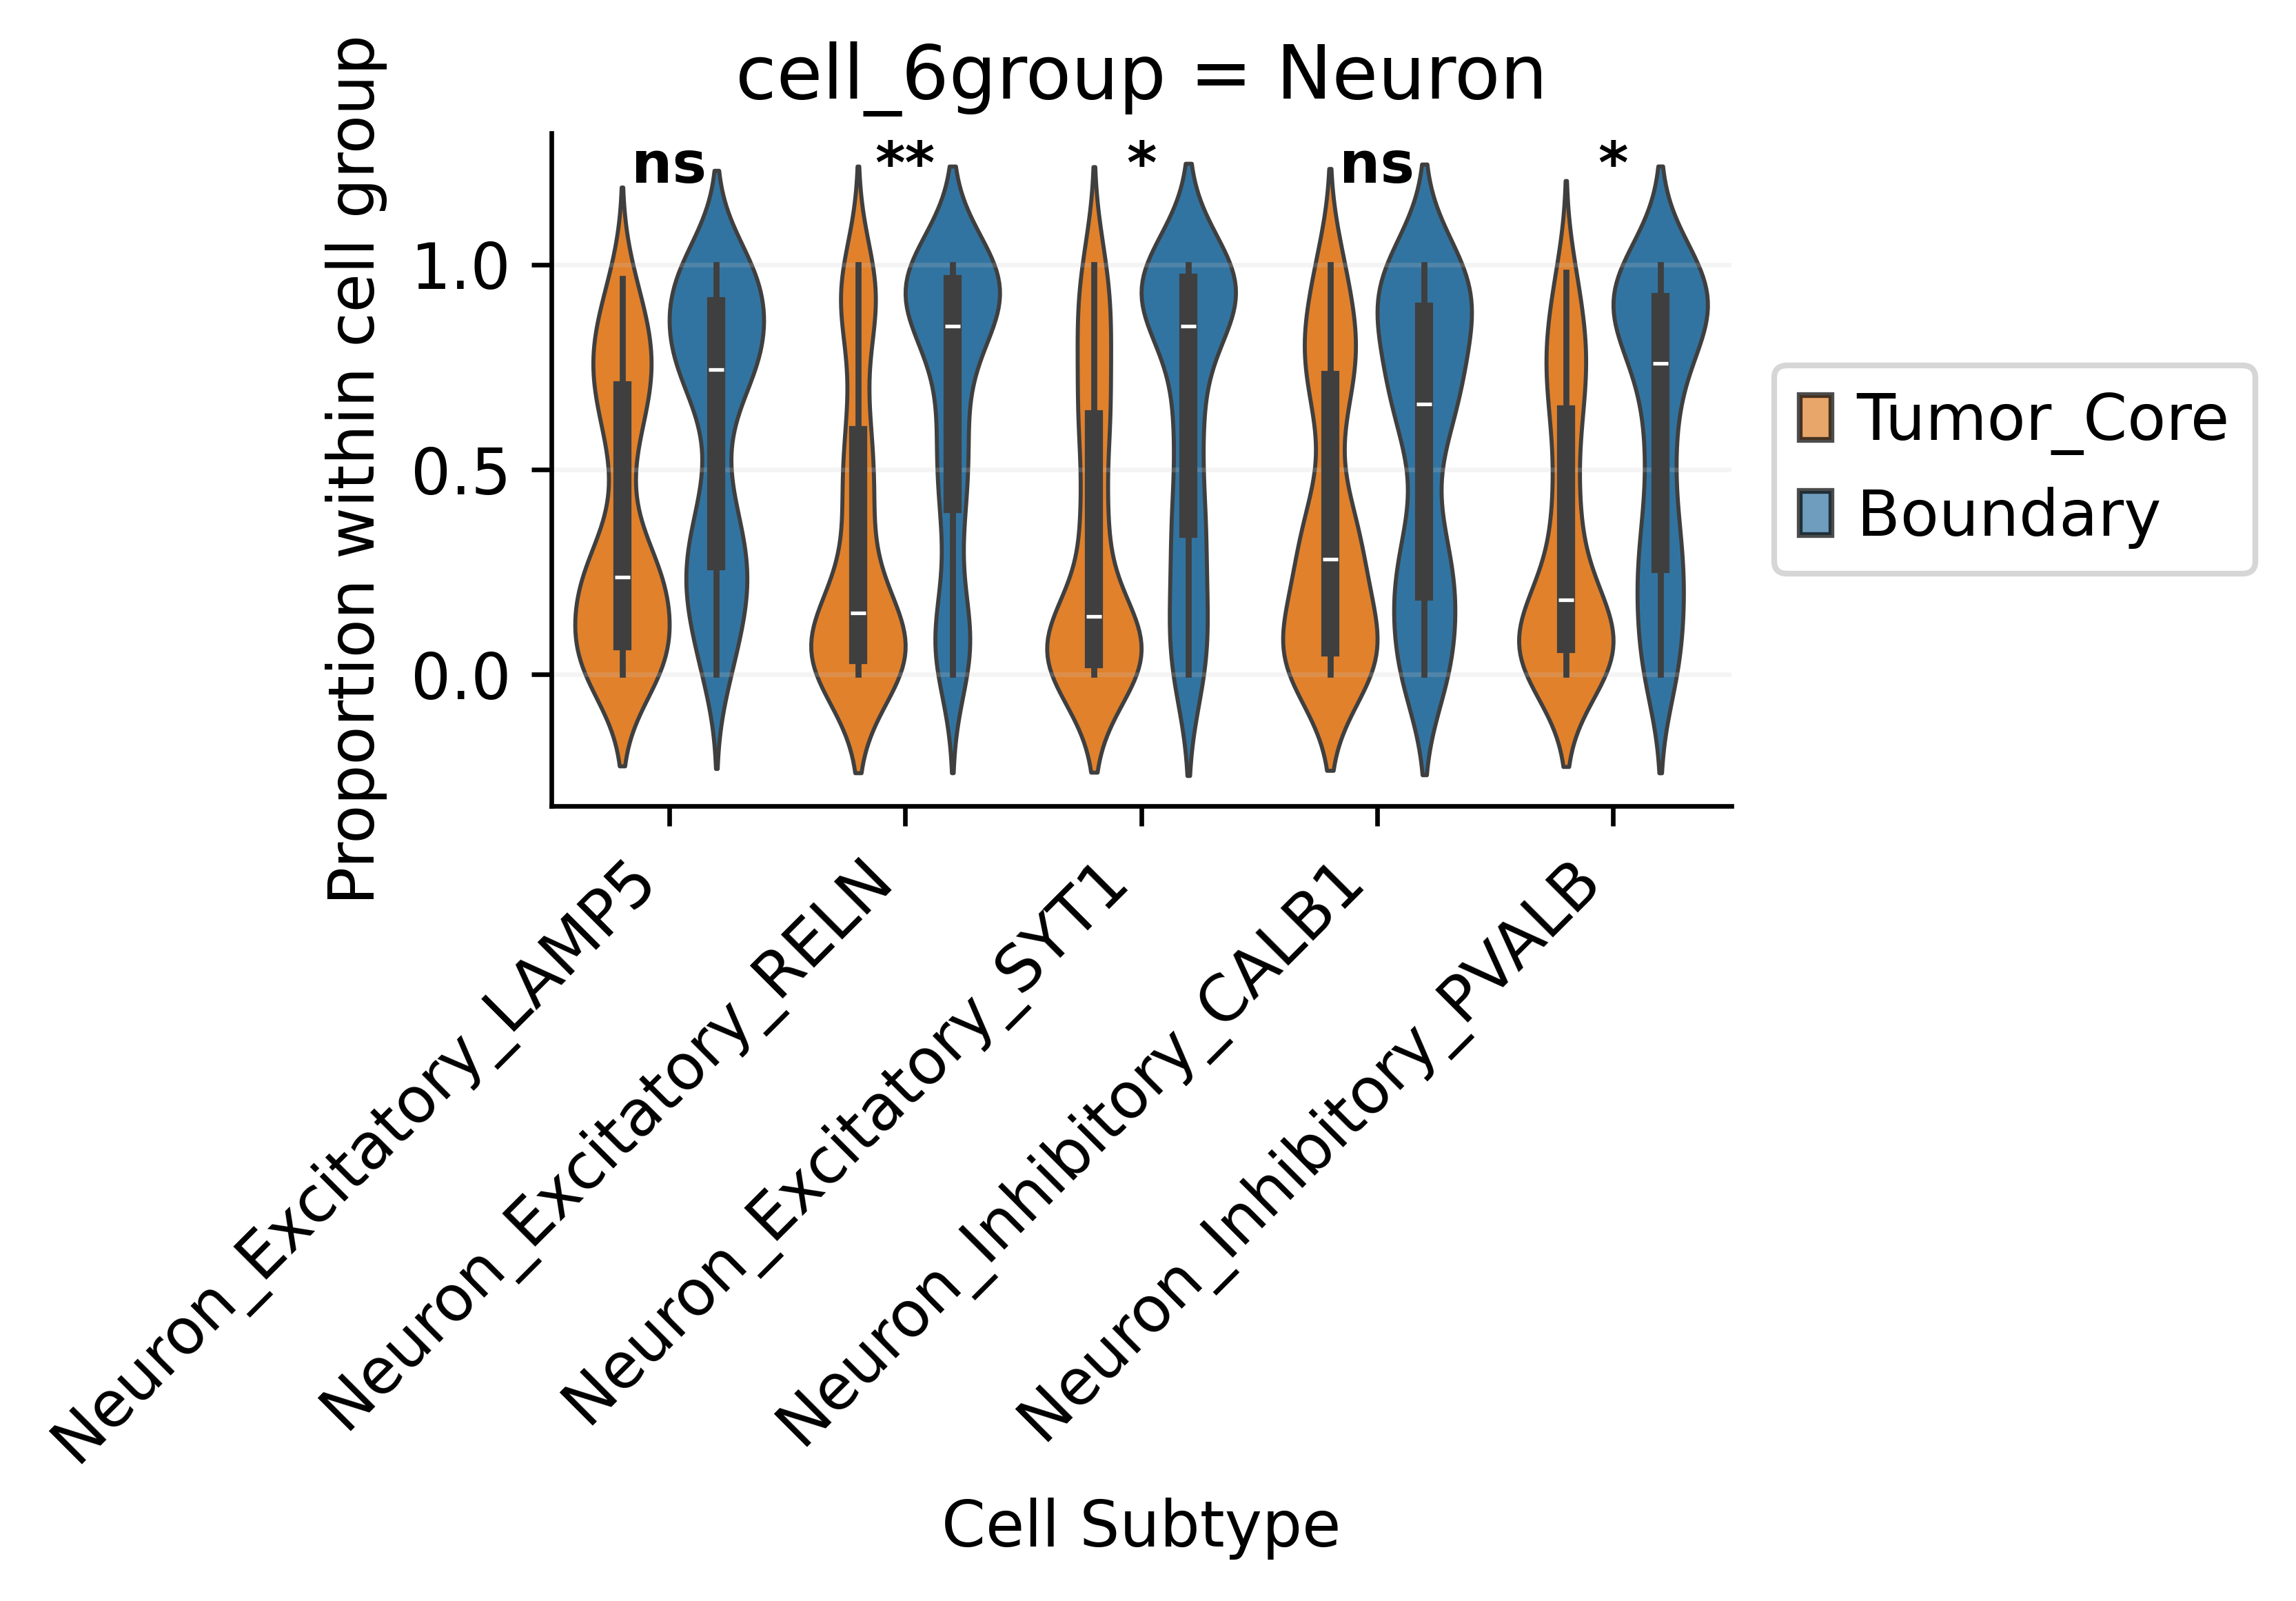

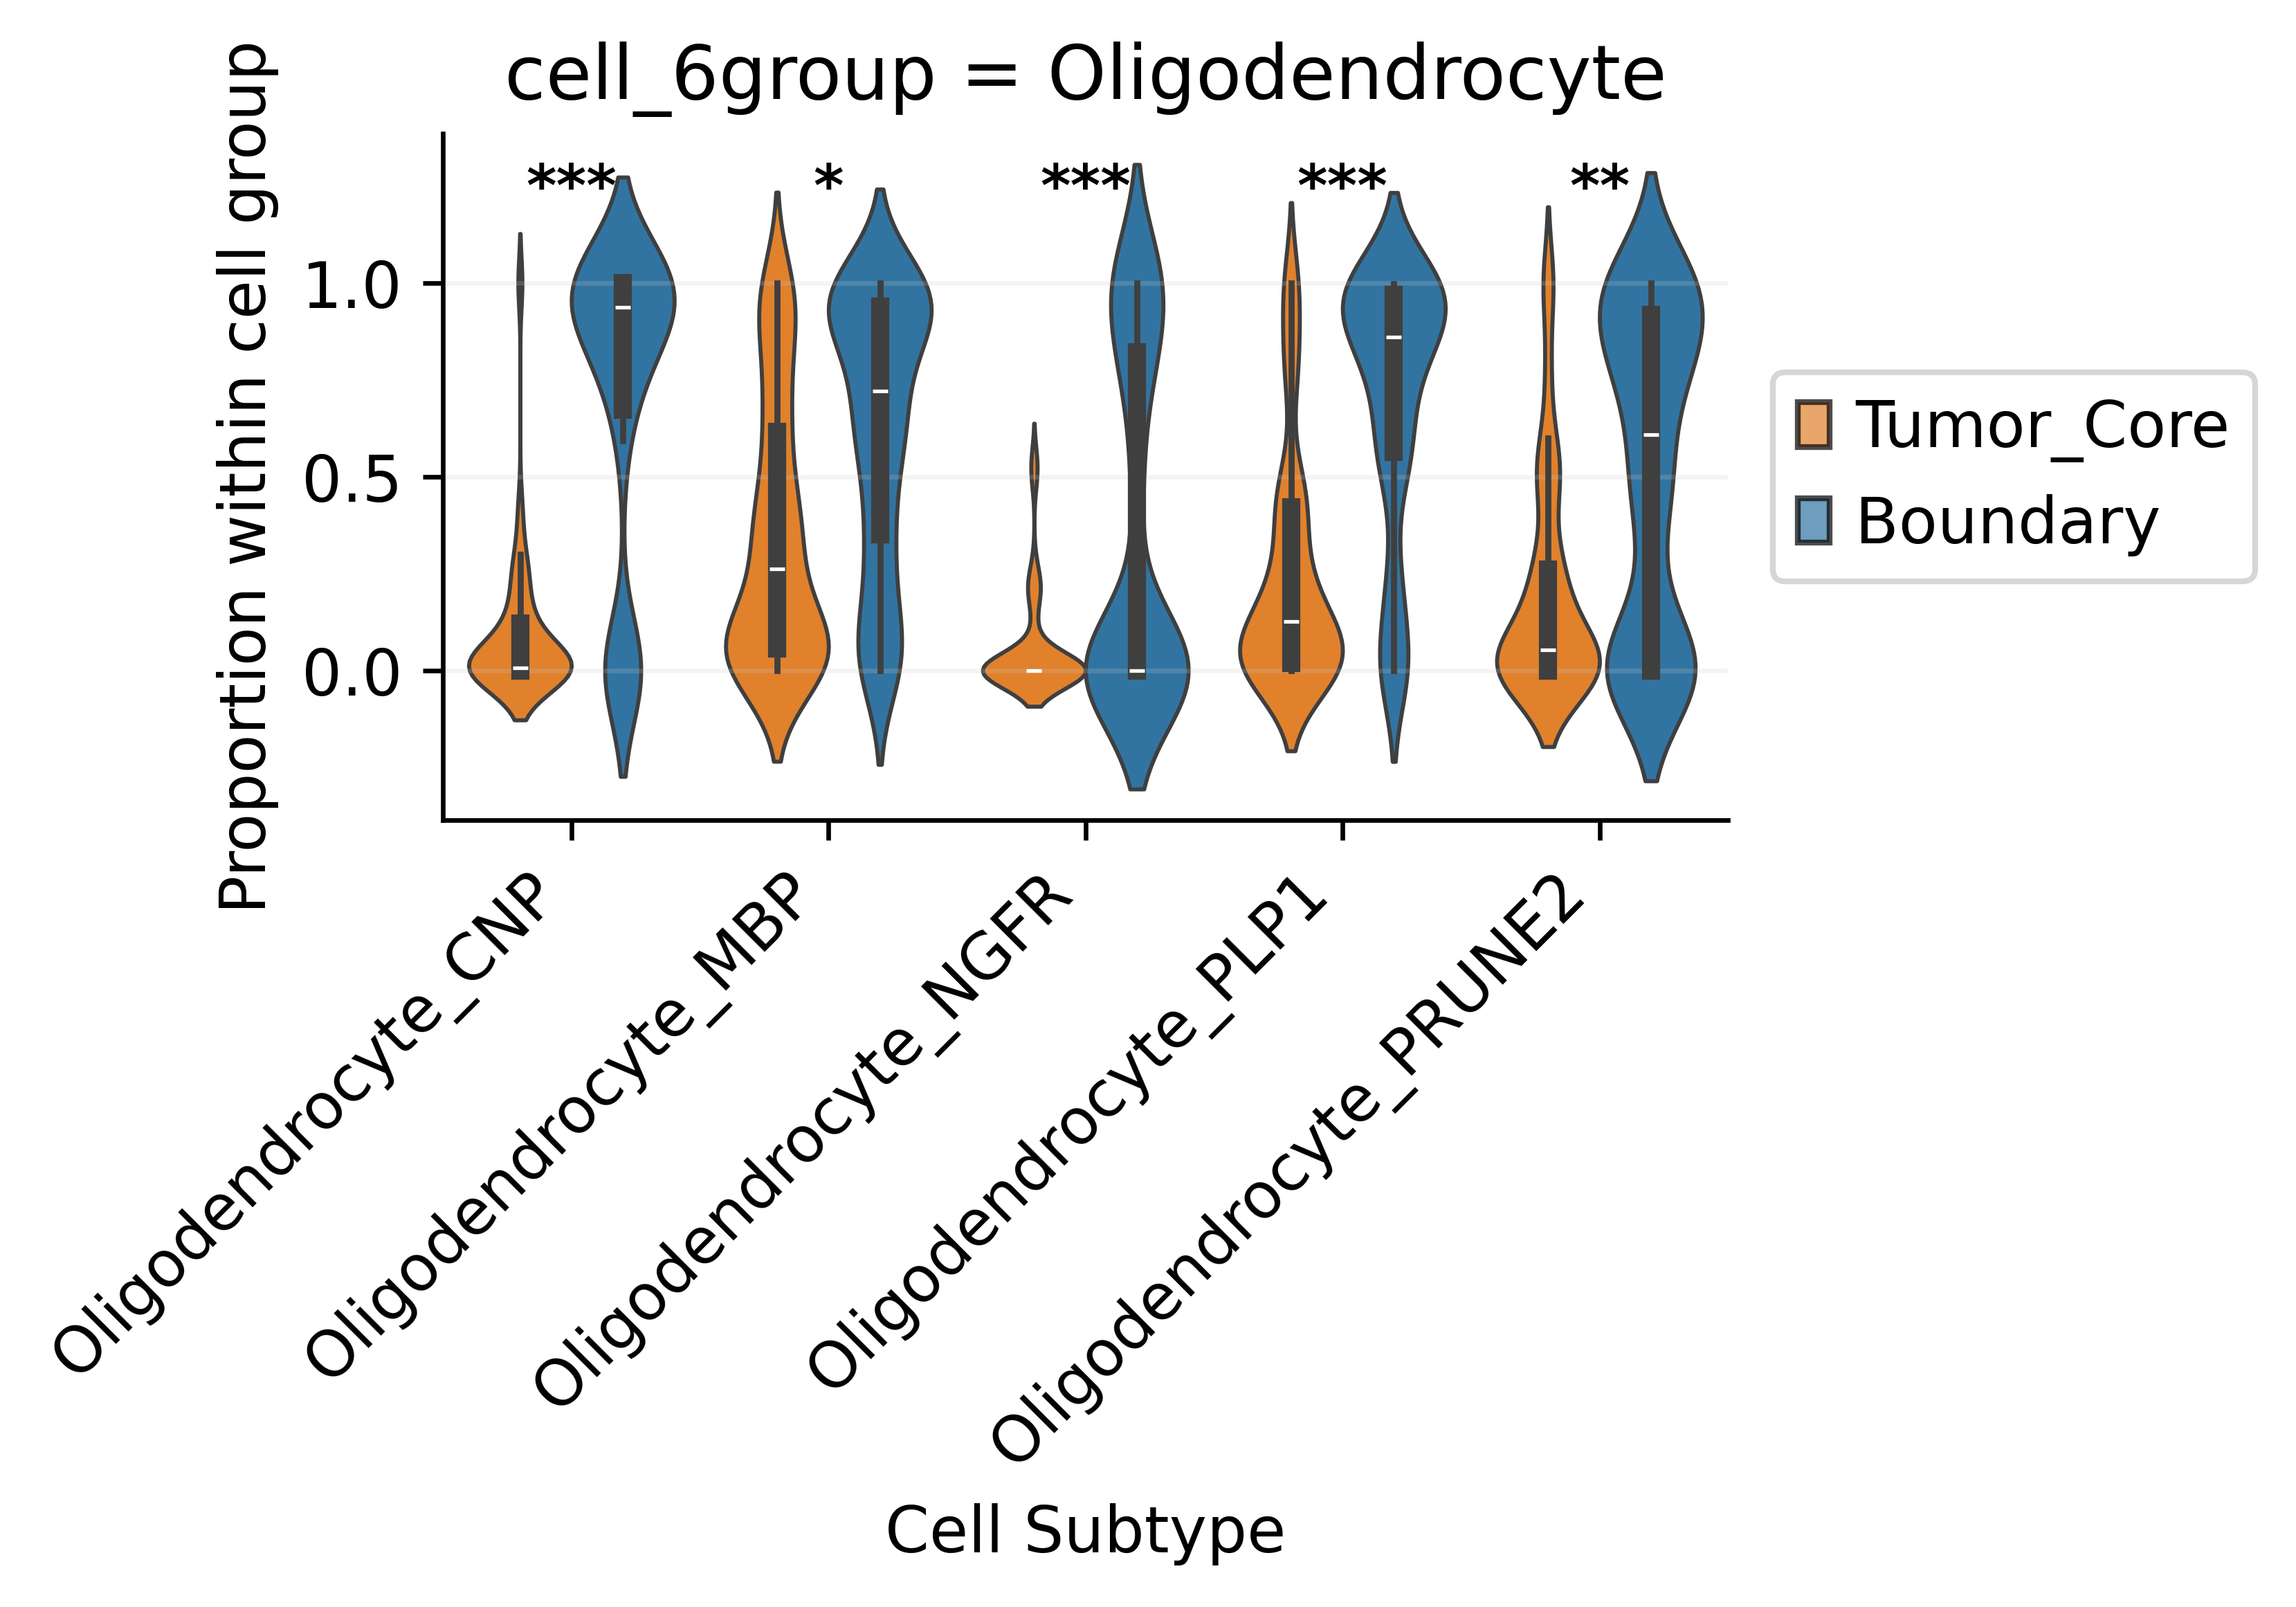

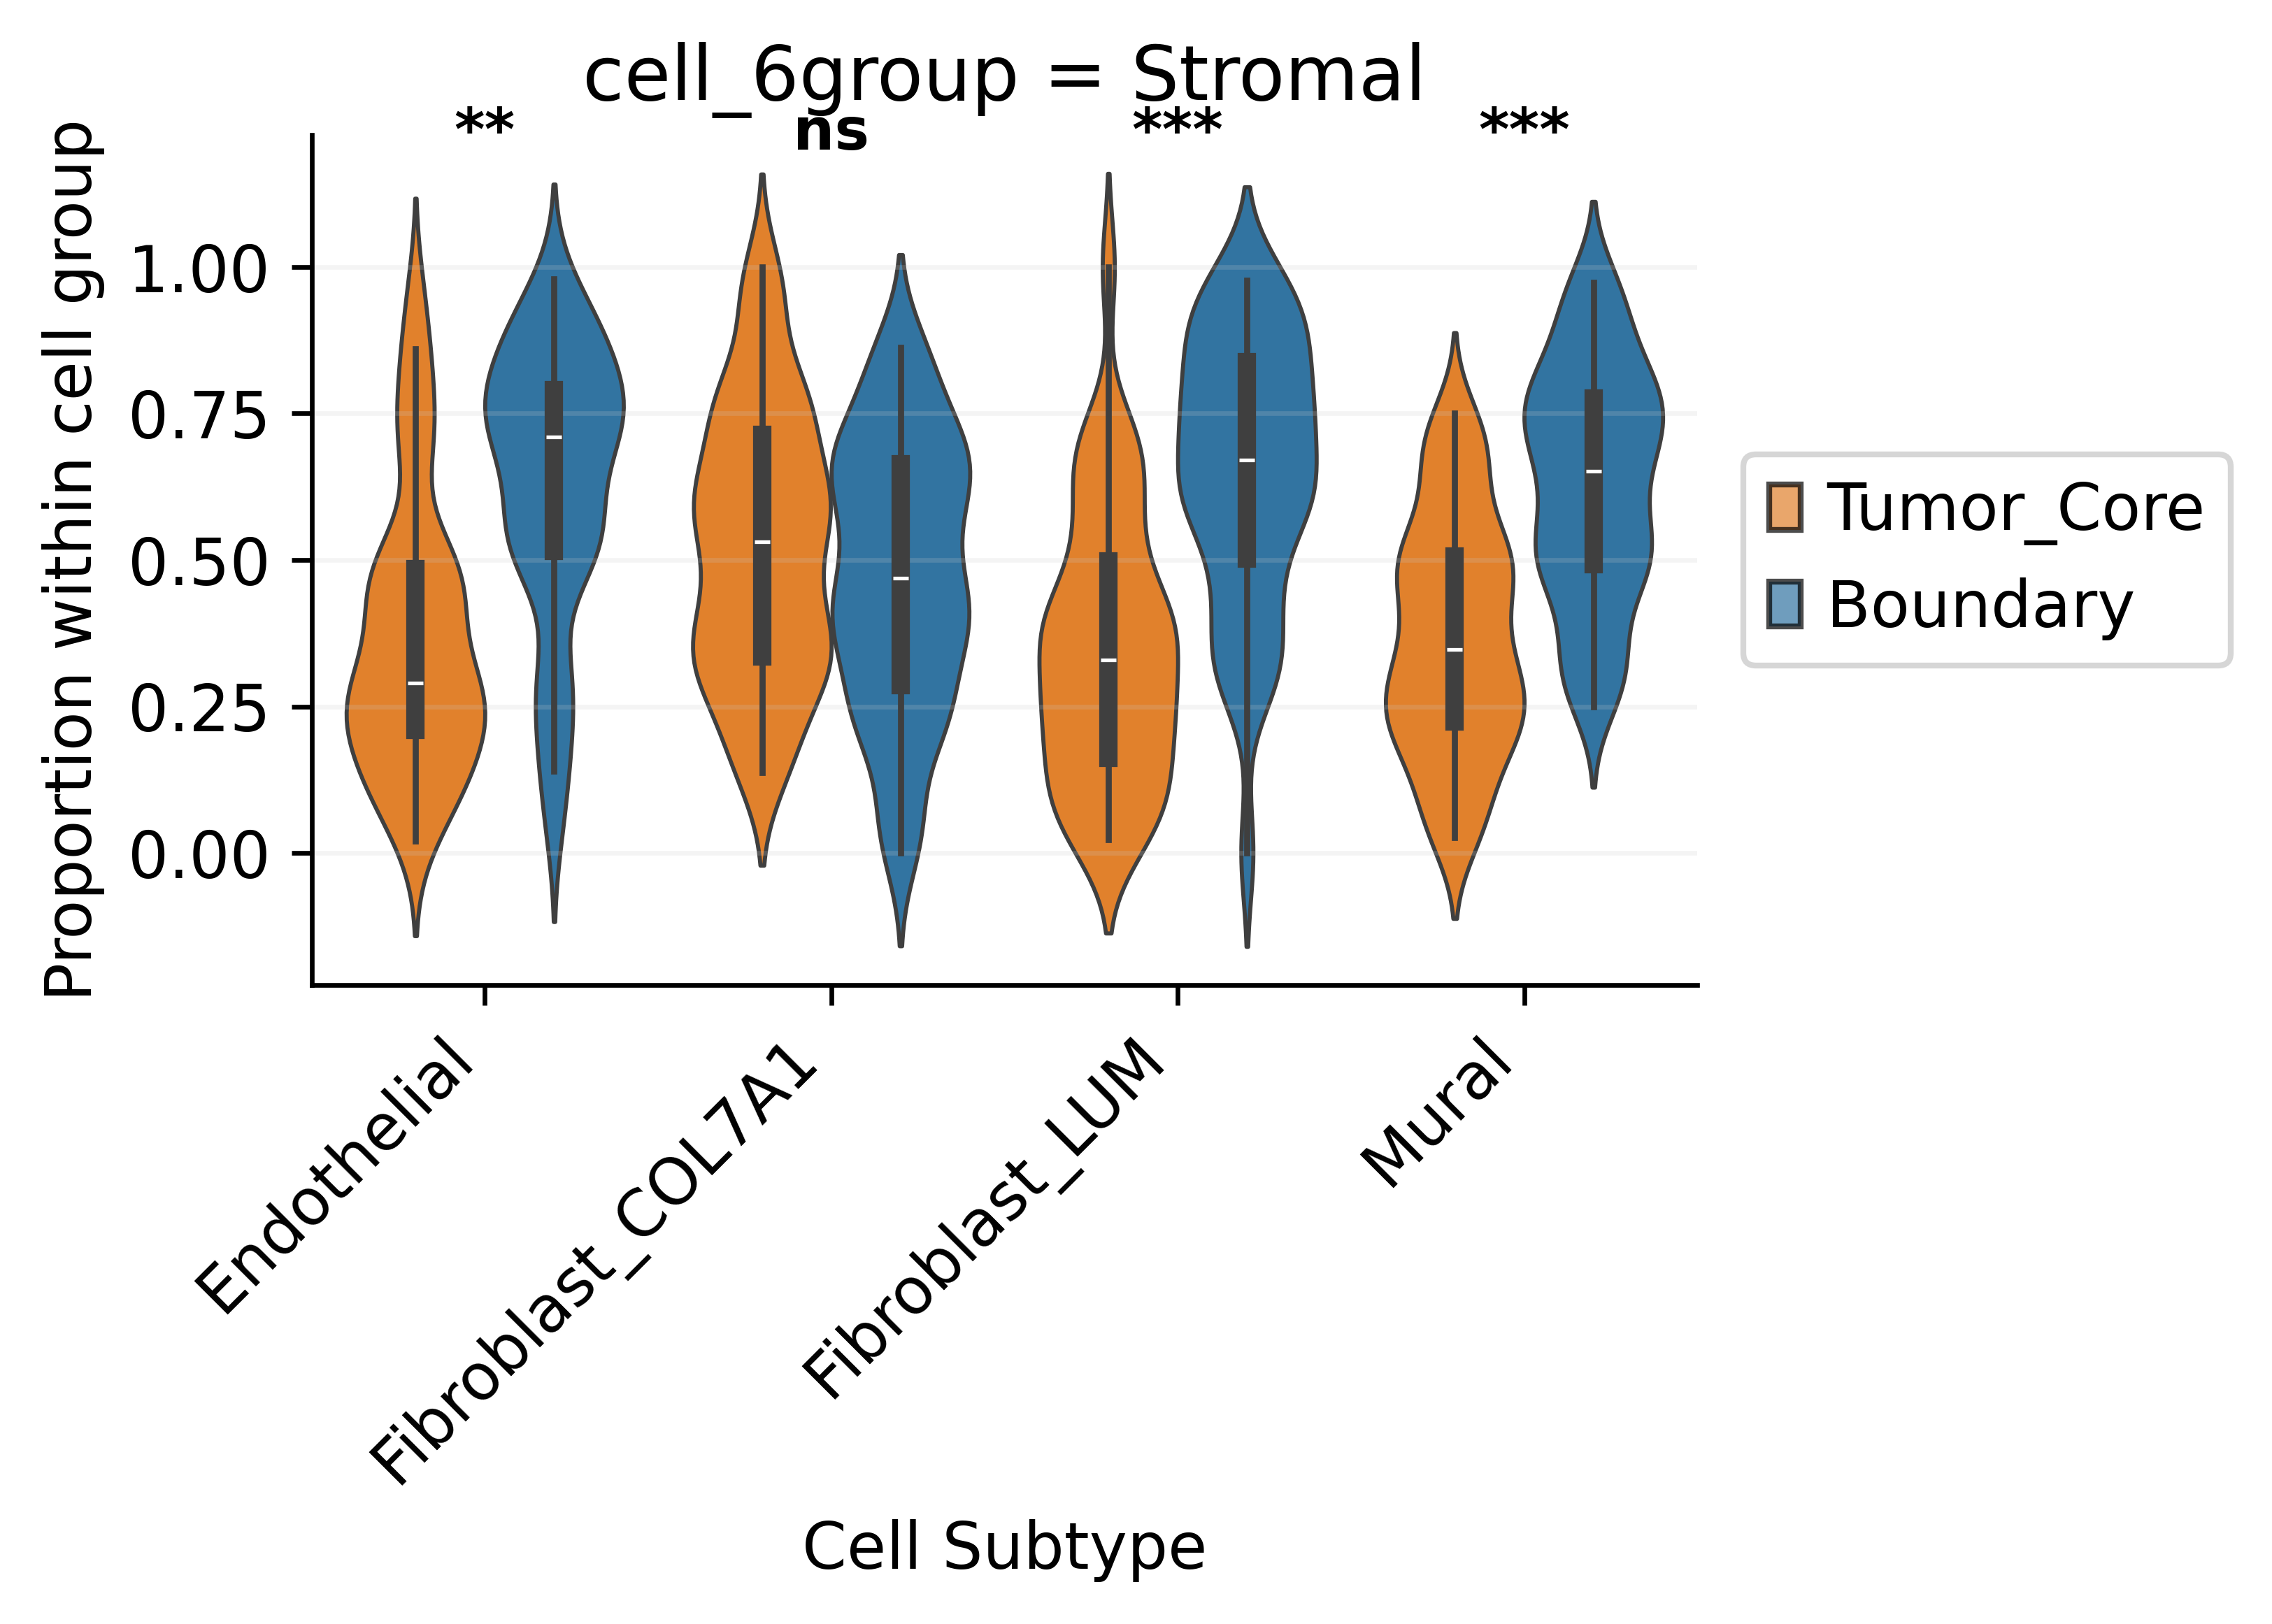

In [ ]:
# 按细胞大类分面绘图
# 比较每样本中， 每种 CellType 在  Tumor_Core 和 Boundary 中的比例

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

# 显著性函数
def get_significance_star(p):
	if p < 0.001:
		return "***"
	elif p < 0.01:
		return "**"
	elif p < 0.05:
		return "*"
	else:
		return "ns"

# 1. 原始数据读取，剔除cell_6group空值
df_raw_all = adata.obs[["sample", "CellType", "cell_6group", "tumor_region_Radius200_36"]].copy()
df_raw_all = df_raw_all.dropna(subset=["cell_6group"])

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
# 遍历每一个细胞大类
group_list = sorted(df_raw_all["cell_6group"].astype(str).unique())
for target_group in group_list:
	# 只保留当前大类的原始数据
	df_raw = df_raw_all[df_raw_all["cell_6group"].astype(str) == target_group].copy()
	# 统计当前分组下：样本-细胞亚型-区域 细胞数量
	count_df = df_raw.groupby(["sample", "CellType", "tumor_region_Radius200_36"]).size().reset_index(name="cell_count")
	# 计算每个样本+细胞亚型下总细胞数
	total_per_sample_ct = count_df.groupby(["sample", "CellType"])["cell_count"].sum().reset_index(name="total_ct")
	count_df = count_df.merge(total_per_sample_ct, on=["sample", "CellType"])
	count_df["proportion"] = count_df["cell_count"] / count_df["total_ct"]
	# 只对当前分组内存在的CellType做组合补齐
	exist_cts = sorted(df_raw["CellType"].unique())  # 排序固定X轴顺序
	all_comb = pd.MultiIndex.from_product(
		[
			df_raw["sample"].unique(),
			exist_cts,
			["Tumor_Core", "Boundary"]
		],
		names=["sample", "CellType", "tumor_region_Radius200_36"]
	).to_frame(index=False)
	
	df_plot = all_comb.merge(
		count_df[["sample", "CellType", "tumor_region_Radius200_36", "proportion"]],
		how="left",
		on=["sample", "CellType", "tumor_region_Radius200_36"]
	).fillna({"proportion": 0})

	if df_plot.empty:
		print(f"分组 {target_group} 无有效数据，跳过")
		continue

	# key必须和分组字符串完全一致，自己改hex色号即可
	region_color_map = {
		"Tumor_Core": "#ff7f0e",   # 肿瘤核心：seaborn 默认第二组橙黄色
		"Boundary": "#1f77b4"      # 边界：seaborn 默认第一组蓝色
	}
	# 自适应画布宽度
	fig_width = max(6, len(exist_cts) * 0.4)
	plt.figure(figsize=(fig_width, 4))
	ax = sns.violinplot(data=df_plot, x="CellType", y="proportion", hue="tumor_region_Radius200_36", inner="box", scale="width", linewidth=0.7, dodge=True, bw_adjust=0.7, order=exist_cts, palette=region_color_map)
	# 白色中空箱线
	for patch in ax.findobj(lambda x: isinstance(x, plt.Rectangle)):
		patch.set_facecolor("white")
		patch.set_edgecolor("black")
	# ax.set_ylim(bottom=0)
	plt.xticks(rotation=45, ha="right")
	ax.set_xlabel("Cell Subtype", fontsize=11)
	ax.set_ylabel("Proportion within cell group", fontsize=11)
	ax.set_title(f"cell_6group = {target_group}", fontsize=13)
	ax.grid(axis="y", alpha=0.2)
	# 带填充色右侧图例
	if len(ax.collections) >= 2:
		core_color = ax.collections[0].get_facecolor()[0]
		bound_color = ax.collections[1].get_facecolor()[0]
		legend_elements = [
			Patch(facecolor=core_color, edgecolor="black", alpha=0.7, label="Tumor_Core"),
			Patch(facecolor=bound_color, edgecolor="black", alpha=0.7, label="Boundary")
		]
		ax.legend(handles=legend_elements, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=True, fontsize=11)
	# 按指定的exist_cts顺序做统计检验，和X轴严格对齐
	p_list = []
	for ct in exist_cts:
		core_vals = df_plot[(df_plot["CellType"] == ct) & (df_plot["tumor_region_Radius200_36"] == "Tumor_Core")]["proportion"].values
		bound_vals = df_plot[(df_plot["CellType"] == ct) & (df_plot["tumor_region_Radius200_36"] == "Boundary")]["proportion"].values
		_, p = stats.ttest_rel(core_vals, bound_vals)
		p_list.append(p)
	# 标注显著性
	y_max = df_plot["proportion"].max() * 1.2
	for idx, ct in enumerate(exist_cts):
		star = get_significance_star(p_list[idx])
		ax.text(idx, y_max, star, ha="center", fontsize=10, fontweight="bold")
	plt.tight_layout(rect=[0, 0, 0.92, 1])
	# 保存每张分组独立图片
	save_fig(f"CellType.proportion.core_vs_boundary.violin.cell_6group.facet.{target_group}", fig_dir)
	# plt.close()
